# Data uncertainty and remote-sensing plant functional diversity: a minimal BOSSE + pyGNDiv experiment

Reproduction of the core mechanism from **Pacheco-Labrador, J., Rossi, C., & Santos, M. J. (2026). *Assessing the impact of data uncertainty on remote sensing estimation of plant functional diversity.* bioRxiv v1, doi:[10.64898/2026.09.21.753123](https://doi.org/10.64898/2026.09.21.753123)**.

**What this notebook does (scope).** Using the authors' own pinned code — **pyBOSSE** (commit `2ae9005`) and **pyGNDiv** (commit `11167fe8`), plus the paper-specific driver `bosse_run.py` (Zenodo [10.5281/zenodo.22872340](https://doi.org/10.5281/zenodo.22872340)) — it:

1. simulates **one** 120×120 BOSSE scene (Continental climate zone, intermediate spatial pattern, meteorological site 0, deterministic seed) with plant-trait and EnMAP reflectance maps (Methods 2.1);
2. perturbs **only the reflectance factors** with one uncertainty type — *constant, decorrelated random noise of 5 % of each band's range* (Methods 2.2, `simulate_uncertainty` in `BOSSE/scsim_uncert.py`), rescaled exactly as the driver does so its RMSE matches the *scaled* variant;
3. recomputes the remote-sensing proxies (**R**, NDVI, NIRv, optically retrieved traits **OT**) from the perturbed reflectance (Methods 2.1);
4. computes **QRao** maps with pyGNDiv's `raoQ_grid` (3×3 moving window, standardization + PCA retaining 98 % variance — Methods 2.3); and
5. regresses the perturbed QRao values against QRao of the **unperturbed plant-trait map** within the scene (1,600 window values) and compares with the no-uncertainty case (Methods 2.4, *within*-site evaluation).

**What is omitted.** The paper's full ensemble (180 scenes × 4 dates × 8 uncertainty types × 100 Monte-Carlo realizations, all four sensors, between-site evaluation, no-preprocessing sensitivity) is out of scope. This is a one-scene, one-date, one-uncertainty-type demonstration, **not** a verification of the paper's dataset-level results.

**Execution status.** Partial demonstration (one scene-date). All scientific functions are the authors' own Python code called from pinned revisions; only the orchestration (the per-scene loop of `bosse_run.py` re-expressed as small cells) and cell glue were written for this notebook. Results shown after "Run all" come from an actual Colab CPU run.

**日本語要約:** このノートブックは、著者らのピン留めされたコード(pyBOSSE・pyGNDiv・`bosse_run.py`)のみを使い、BOSSE で生成した 1 シーン・1 日付の植物形質マップと EnMAP 反射率に、定数・非相関のランダム誤差(相対 5 %)を与え、pyGNDiv の QRao(3×3 ウィンドウ、標準化 + PCA 98 %)を計算して、無撹乱の植物形質 QRao と回帰比較する最小デモです。論文の全アンサンブル実験は対象外です。

## Runtime selection

**Use a standard CPU runtime** (Runtime → Change runtime type → CPU). This pipeline uses no deep-learning framework: the "neural networks" are scikit-learn MLP emulators shipped as joblib pickles and executed on CPU by the authors' code, the uncertainty simulation is NumPy/SciPy, and pyGNDiv's window loops are numba-jitted. A GPU provides no benefit here.

Expected resources (see report): ~2 MB of repository/model downloads, dependency installs, and a total wall time of roughly 10–25 minutes, dominated by scene initialization.

**日本語:** 標準 CPU ランタイムを選択してください。GPU は不要です(使用する NN は scikit-learn 製)。所要時間は目安として 10〜25 分程度です。

In [ ]:
import os, platform, multiprocessing, time
print('Python:', platform.python_version())
print('CPU cores:', multiprocessing.cpu_count())
try:
    mem_kb = os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES')
    print(f'RAM: ~{mem_kb / 2**30:.1f} GiB')
except Exception as e:
    print('RAM unknown:', e)
t_start = time.time()

Python: 3.13.16
CPU cores: 2
RAM: ~12.7 GiB


## 1 · Dependencies

The pinned pyBOSSE code imports the following packages that are not always preinstalled on Colab: `pyet` (potential evapotranspiration), `python-rle` (imported as `rle`), `nlmpy` (neutral landscape models), `distinctipy` (plotting colors), `h5netcdf`/`netCDF4` (xarray backends for the ERA5-Land NetCDF input). `wpca` and `numba` are required by pyGNDiv; the pyGNDiv wheel itself is installed separately below.

**日本語:** 著者コードが必要とする追加パッケージをインストールします(pyet, python-rle, nlmpy, distinctipy, NetCDF バックエンド、pyGNDiv 用の wpca)。

In [ ]:
%pip install -q pyet python-rle nlmpy distinctipy wpca more-itertools h5netcdf netCDF4
import importlib
for m in ['pyet', 'rle', 'nlmpy', 'distinctipy', 'wpca', 'xarray', 'netCDF4', 'numba', 'joblib', 'shapely', 'skimage']:
    mod = importlib.import_module(m)
    print(f'{m:12s} OK', getattr(mod, '__version__', ''))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 901.0/901.0 kB 13.6 MB/s eta 0:00:00


  Preparing metadata (setup.py) ... done


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 94.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 70.8 MB/s eta 0:00:00


pyet         OK 1.5.0
rle          OK 
nlmpy        OK 
distinctipy  OK 1.3.4


wpca         OK 0.1
xarray       OK 2025.12.0
netCDF4      OK 1.7.5.1


numba        OK 0.61.2
joblib       OK 1.6.0
shapely      OK 2.2.0
skimage      OK 0.25.2


## 2 · Pinned author code and inputs (pyBOSSE @ `2ae9005`)

We fetch the authors' repository at the **exact verified commit** `2ae90057dedbc477fdf4463e2aa638d0bbbf54fc` with a *partial clone* (`--filter=blob:none --no-checkout`) and a *sparse checkout* restricted to the directories the minimal experiment needs: `BOSSE/` (code), the **EnMAP spectral response function**, the **Continental site-0 ERA5-Land meteorological file**, and `BOSSE_models/` (the emulator/GMM weights the code loads). This avoids the larger meteorological archive (Zenodo 14717038) and unrelated sensor files. All bytes land under `/content` on the Colab VM.

After checkout we assert the detached HEAD equals the pinned commit and check the expected byte sizes of the key inputs.

**日本語:** 著者のリポジトリを、検証済みコミットに部分的(partial clone + sparse checkout)に取得します。必要なコード・EnMAP SRF・Continental の気象ファイル 1 本・モデル重みのみを取得し、コミットとファイルサイズを検証します。

In [ ]:
import subprocess, os

WORK = '/content/work'
PYBOSSE = f'{WORK}/pyBOSSE'
COMMIT = '2ae90057dedbc477fdf4463e2aa638d0bbbf54fc'
os.makedirs(WORK, exist_ok=True)

if not os.path.isdir(f'{PYBOSSE}/.git'):
    subprocess.run(['git', 'clone', '--filter=blob:none', '--no-checkout',
                    'https://github.com/JavierPachecoLabrador/pyBOSSE', PYBOSSE],
                   check=True)
subprocess.run(['git', '-C', PYBOSSE, 'sparse-checkout', 'init', '--no-cone'], check=True)
subprocess.run(['git', '-C', PYBOSSE, 'sparse-checkout', 'set',
                '/BOSSE/**',
                '/BOSSE_inputs/Sensors/EnMAP_SpectralFeatures.txt',
                '/BOSSE_inputs/Meteo_ERA5Land/BOSSE_meteo_Continental_0.nc',
                '/BOSSE_models/**'], check=True)
if not subprocess.run(['git', '-C', PYBOSSE, 'checkout', '--detach', COMMIT],
                      capture_output=True).returncode == 0:
    # fetch the pinned commit explicitly if it is not the fetched tip
    subprocess.run(['git', '-C', PYBOSSE, 'fetch', '--filter=blob:none', 'origin', COMMIT],
                   check=True)
    subprocess.run(['git', '-C', PYBOSSE, 'checkout', '--detach', 'FETCH_HEAD'], check=True)
head = subprocess.run(['git', '-C', PYBOSSE, 'rev-parse', 'HEAD'],
                      capture_output=True, text=True, check=True).stdout.strip()
assert head == COMMIT, f'checkout mismatch: {head}'

expected = {
    'BOSSE/bosse.py': 22453,
    'BOSSE/scsim_uncert.py': 12485,
    'BOSSE_inputs/Sensors/EnMAP_SpectralFeatures.txt': 2953,
    'BOSSE_inputs/Meteo_ERA5Land/BOSSE_meteo_Continental_0.nc': 2190087,
    'BOSSE_models/NNR_nlyr2_Hy/NNR_Slut_LAI020.joblib': 704823,
    'BOSSE_models/NNRinv_nlyr2_EnMAP/NNRinv_Slut_LAI020.joblib': 282994,
}
for rel, size in expected.items():
    got = os.path.getsize(f'{PYBOSSE}/{rel}')
    assert got == size, f'{rel}: expected {size} B, got {got} B'
    print(f'{rel}: {got} B OK')
print('pyBOSSE pinned at', head)

BOSSE/bosse.py: 22453 B OK
BOSSE/scsim_uncert.py: 12485 B OK
BOSSE_inputs/Sensors/EnMAP_SpectralFeatures.txt: 2953 B OK
BOSSE_inputs/Meteo_ERA5Land/BOSSE_meteo_Continental_0.nc: 2190087 B OK
BOSSE_models/NNR_nlyr2_Hy/NNR_Slut_LAI020.joblib: 704823 B OK
BOSSE_models/NNRinv_nlyr2_EnMAP/NNRinv_Slut_LAI020.joblib: 282994 B OK
pyBOSSE pinned at 2ae90057dedbc477fdf4463e2aa638d0bbbf54fc


## 3 · Pinned pyGNDiv (`11167fe8`)

pyGNDiv provides `raoQ_grid` — the exact function the paper's driver uses to compute QRao maps (3×3 window, standardization + PCA retaining 98 % of variance by default). We install the authors' repository at the verified commit `11167fe8b0574982029d1961801d85971e1283fe`. We use `--no-deps` because the legacy `setup.py` lists `python-math`, which is not actually imported; its real dependencies (numpy, scikit-learn, scipy, numba, wpca) are already present.

**日本語:** QRao 計算の本体である pyGNDiv を、検証済みコミットからインストールします(実際に import される依存は明示的に揃えてあるため `--no-deps` で入れます)。

In [ ]:
%pip install -q --no-deps git+https://github.com/JavierPachecoLabrador/pyGNDiv-master.git@11167fe8b0574982029d1961801d85971e1283fe
import pyGNDiv, pyGNDiv.pyGNDiv_imagery as gndi
print('pyGNDiv at:', pyGNDiv.__file__)

  Preparing metadata (setup.py) ... done


pyGNDiv at: /usr/local/lib/python3.13/dist-packages/pyGNDiv/__init__.py


## 4 · Imports and driver helpers (copied verbatim from `bosse_run.py`)

We import the BOSSE model classes and copy three small helpers **verbatim** from the paper's driver `bosse_run.py` (Zenodo 22872340), citing the exact line ranges: `find_minimum_distance` (L113–119, date selection at a GSI percentile), `generate_RF` (L129–153, chunked reflectance prediction for a 120×120 scene), `cube_var_rmse` (L381–386, per-band RMSE used for the constant/scaled rescaling), and `assess_predobs` (L361–380, the predicted–observed statistics R², r, RMSE, RRMSE, NRMSE, MAE, slope, bias).

**日本語:** BOSSE のクラスを読み込み、駆動スクリプト `bosse_run.py` から日付選択・反射率予測・RMSE 計算・統計量評価の 4 つの関数をそのまま(行番号付きで)コピーします。

In [ ]:
import sys, copy, time
import numpy as np
import pandas as pd

sys.path.insert(0, '/content/work/pyBOSSE')

from BOSSE.bosse import BosseModel
from BOSSE.helpers import set_up_paths_and_inputs, get_RSensor_bands
from BOSSE.scsim_rtm import get_ndvi_nirv
from BOSSE.scsim_uncert import simulate_uncertainty
from pyGNDiv import pyGNDiv_imagery as gndi

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import linregress


# --- verbatim from bosse_run.py L113-119 -------------------------------------
def find_minimum_distance(X_, xi):
    dist_ = np.abs(X_ - xi)
    I_ = np.where(dist_ == dist_.min())[0][0]

    return(I_)

# --- verbatim from bosse_run.py L129-153 -------------------------------------
def generate_RF(bosse_M, PT_, im_sz, inputs_i, sensor='EnMAP'):
    if im_sz <= 90:
        RF_ = bosse_M.pred_refl_factors(PT_, inputs_i['scene_sz'],
                                        sp_res=inputs_i['spat_res'],
                                        sensor=sensor)
    else:
        RF_ = np.full((im_sz, im_sz, bosse_M.sensor_srf[sensor][0].shape[1]),
                      np.nan)

        plot_sz = im_sz // 2
        for x_ in range(0, im_sz, plot_sz):
            for y_ in range(0,  im_sz, plot_sz):
                Ix_, Iy_ = generate_mask(x_, y_, im_sz, plot_sz)

                tmp = bosse_M.pred_refl_factors(PT_[Iy_][:, Ix_],
                                                plot_sz,
                                                sp_res=inputs_i['spat_res'],
                                                sensor=sensor)
                RF_[y_:y_+plot_sz, x_:x_+plot_sz] = copy.deepcopy(tmp)

    return(RF_)

# --- verbatim from bosse_run.py L120-128 (helper of generate_RF) -------------
def generate_mask(x0, y0, sz, sz_mask):
    Imask_x = np.zeros(sz, dtype=bool)
    Imask_y = np.zeros(sz, dtype=bool)
    Imask_x[x0:x0 + sz_mask] = True
    Imask_y[y0:y0 + sz_mask] = True

    return(Imask_x, Imask_y)

# --- verbatim from bosse_run.py L381-386 -------------------------------------
def cube_var_rmse(cube):
    shp = cube.shape
    rmse_v = np.sqrt(np.mean(cube.reshape((shp[0] * shp[1], shp[2])) ** 2, axis=0))

    return(rmse_v)

# --- verbatim from bosse_run.py L361-380 -------------------------------------
def assess_predobs(pred_i, obs_i):
    I_ = np.isfinite(pred_i.reshape(-1) * obs_i.reshape(-1))
    pred_ = pred_i[I_]
    obs_ = obs_i[I_]

    n_ = pred_.size
    R2_ = r2_score(obs_, pred_)
    rmse_ = mean_squared_error(obs_, pred_) ** .5
    rrmse_  = 100 * rmse_ / obs_.mean()
    nrmse_ = 100 * rmse_ / (obs_.max() - obs_.min())
    mae_ = mean_absolute_error(obs_, pred_)
    mod_ = linregress(pred_.reshape(-1), obs_.reshape(-1))

    out_ = [n_, R2_, mod_.rvalue, mod_.pvalue, rmse_, rrmse_, nrmse_, mae_,
            mod_.slope, mod_.intercept]

    return(out_)

print('BOSSE + pyGNDiv imports and helpers ready')

BOSSE + pyGNDiv imports and helpers ready


/content/work/pyBOSSE/BOSSE/plotter.py:29: SyntaxWarning: invalid escape sequence '\m'
  'Cab': ['$C_{\\rm ab}$', '$\\rm \mu mol cm^{-2}$'],
/content/work/pyBOSSE/BOSSE/plotter.py:30: SyntaxWarning: invalid escape sequence '\m'
  'Cca': ['$C_{\\rm ca}$', '$\\rm \mu mol cm^{-2}$'],
/content/work/pyBOSSE/BOSSE/plotter.py:31: SyntaxWarning: invalid escape sequence '\m'
  'Cant': ['$C_{\\rm ant}$', '$\\rm \mu mol cm^{-2}$'],
/content/work/pyBOSSE/BOSSE/plotter.py:40: SyntaxWarning: invalid escape sequence '\m'
  'Vcmo': ['$V_{\\rm cmo}$', '$\\rm \mu molC cm^{-2} s^{-1}$'],
/content/work/pyBOSSE/BOSSE/plotter.py:47: SyntaxWarning: invalid escape sequence '\p'
  'BSMlat': ['$\phi_{\\rm BSM}$', '$\degree$'],
/content/work/pyBOSSE/BOSSE/plotter.py:47: SyntaxWarning: invalid escape sequence '\d'
  'BSMlat': ['$\phi_{\\rm BSM}$', '$\degree$'],
/content/work/pyBOSSE/BOSSE/plotter.py:48: SyntaxWarning: invalid escape sequence '\l'
  'BSMlon': ['$\lambda_{\\rm BSM}$', '$\degree$'],
/content/work/py

## 5 · Configure and build the BOSSE model

This reproduces the driver's configuration (`bosse_run.py`, `main()` L2393+): a 120×120 scene with up to 60 species, EnMAP as sensor, and the model class `BosseModel` constructed with the EnMAP sensor response functions. Construction loads the GMM foliar-trait model, the reflectance/fluorescence/LST/function emulators, the EnMAP trait-retrieval network, and the soil-resistance interpolator from `BOSSE_models/`. Timing is measured and reported.

**日本語:** `bosse_run.py` の main() と同じ設定(120×120、最大 60 種、EnMAP)で `BosseModel` を構築します。各エミュレータ重みの読み込み時間を計測します。

In [ ]:
t0 = time.time()
(inputs_, paths_) = set_up_paths_and_inputs(
    None, '/content/work/bosse_out', create_out_folder=False,
    pth_root='/content/work/pyBOSSE/',
    pth_inputs='/content/work/pyBOSSE/BOSSE_inputs/',
    pth_models='/content/work/pyBOSSE/BOSSE_models/')
# --- driver main() configuration (bosse_run.py L2415-2418) ---
inputs_['scene_sz'] = 120
inputs_['S_max'] = 60
inputs_['sensor'] = 'EnMAP'
print('inputs:', {k: inputs_[k] for k in
                  ('scene_sz', 'S_max', 'sensor', 'sp_pattern', 'clim_zone',
                   'spat_res', 'rseed_num')})
print(f'paths set up in {time.time() - t0:.1f} s')

inputs: {'scene_sz': 120, 'S_max': 60, 'sensor': 'EnMAP', 'sp_pattern': 'intermediate', 'clim_zone': 'Continental', 'spat_res': 100, 'rseed_num': 100}
paths set up in 0.0 s


With the configuration and paths in place we now instantiate the model. `BosseModel.__init__` loads the GMM foliar-trait model, the reflectance/fluorescence/LST/ecosystem-function emulators, the EnMAP trait-retrieval network, and the soil-resistance interpolator from `BOSSE_models/`, then times the result.

**日本語:** 設定をもとに `BosseModel` を構築します。各エミュレータ重みの読み込み時間を計測します。

In [ ]:
t0 = time.time()
bosse_M = BosseModel(inputs_, paths_, sensor_srf_list=['EnMAP'])
print(f'BosseModel built in {time.time() - t0:.1f} s')

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator GaussianMixture from version 1.3.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.3.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator PCA from version 1.3.1 when using version 1.6.1. This might lead to breaking code or invalid re

BosseModel built in 2.1 s


## 6 · Initialize the deterministic scene

`initialize_scene(0, seednum_=1)` reproduces the driver's first Continental/intermediate scene: meteorological site **0** (`BOSSE_meteo_Continental_0.nc`) and species seed `seednum_ = i_ + j_ = 0 + 1 = 1` (`bosse_run.py` L527: `seednum_= i_ + j_`). This generates the species map, PFT distribution, trait bounds, and the season-long Growing Season Index (GSI) used for date selection. This is typically the slowest step of the notebook.

**日本語:** 駆動スクリプトと同じシード(`seednum_=1`、気象サイト 0)でシーンを初期化します。種マップや GSI 季節曲線が生成されます。ここが最も時間のかかる工程です。

In [ ]:
t0 = time.time()
bosse_M.initialize_scene(0, seednum_=1, verbose=True)
print(f'Scene initialized in {time.time() - t0:.1f} s; '
      f'S_max={bosse_M.S_max}, ts_days={bosse_M.ts_days}')

########################################################################
Initializing scene 0 ...
	Loading meteo data...


		elapsed time 12.03 seconds.
	Generating the Scene...


		elapsed time 19.17 seconds.
Total elapsed time 31.20 seconds.
Scene initialized in 31.2 s; S_max=32, ts_days=730


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 7 · EnMAP bands without water vapour + trait-retrieval model

Exactly as in `prepare_scene` (`bosse_run.py` L95–105), we reload the EnMAP spectral response functions **removing water-vapour bands** on the scene model, and build a second `BosseModel` (`bosse_Mot`) configured for **optical trait retrieval from EnMAP** (`sensor_retrieval='EnMAP'`, `sensor_rmWVb=True`), which loads `NNRinv_nlyr2_EnMAP`.

**日本語:** `prepare_scene` と同様に、水蒸気吸収バンドを除いた EnMAP SRF を再読み込みし、EnMAP 用の光学形質推定モデル(`NNRinv_nlyr2_EnMAP`)を持つ 2 つ目のモデルを作成します。

In [ ]:
t0 = time.time()
bosse_M.paths_ = copy.deepcopy(paths_)
bosse_M.sensor_rmWVb = True
bosse_M.sensor_srf['EnMAP'] = get_RSensor_bands(
    'EnMAP', paths_['0_sensors'], rmWVb=bosse_M.sensor_rmWVb)
wl = bosse_M.sensor_srf['EnMAP'][1]
print(f'EnMAP bands (WV removed): {len(wl)} bands, {wl[0]:.0f}-{wl[-1]:.0f} nm')

bosse_Mot = BosseModel(inputs_, paths_, sensor_retrieval='EnMAP',
                       sensor_srf_list=['EnMAP'], sensor_rmWVb=True)
print(f'Trait-retrieval model ready in {time.time() - t0:.1f} s')

EnMAP bands (WV removed): 197 bands, 418-2445 nm
Trait-retrieval model ready in 0.2 s


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator GaussianMixture from version 1.3.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.3.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator PCA from version 1.3.1 when using version 1.6.1. This might lead to breaking code or invalid re

## 8 · Select the simulation date from the GSI percentiles

The driver evaluates four dates at the 100th, 85th, 60th and 45th percentiles of the scene's mean Growing Season Index (`gsi_percent=[100, 85, 60, 45]`, `bosse_run.py` L395) and picks the day nearest to each percentile (`find_minimum_distance`). Here we use the **peak-GSI date** (100th percentile, i.e. the first date the driver processes).

**日本語:** ドライバと同じ方法で、シーン平均 GSI の 100 パーセンタイル(生育期ピーク)に最も近い日を選択します。

In [ ]:
gsi_ = bosse_M.GSI_all.mean(axis=1).mean(axis=1)
gsi_perc = np.percentile(gsi_, [100, 85, 60, 45])   # driver default
t_ = find_minimum_distance(gsi_, gsi_perc[0])
print('GSI percentiles [100,85,60,45]:', np.round(gsi_perc, 3))
print(f'selected day index t_ = {t_} (peak GSI = {gsi_[t_]:.3f})')

GSI percentiles [100,85,60,45]: [0.87  0.855 0.719 0.53 ]
selected day index t_ = 240 (peak GSI = 0.870)


## 9 · Simulate plant traits and EnMAP reflectance at the selected date

Following the driver (`bosse_run.py` L519–525): `pred_scene_timestamp` produces the full scene state `X_` (plant traits, soil, meteorology) at day `t_`, and `generate_RF` predicts **EnMAP reflectance factors** from it (the 120×120 case is processed in four 60×60 chunks, L129–153). We then keep the first 12 plant-trait variables (`PT_ = PT_[:, :, :12]`, the foliar/structural traits used as the QRao reference), and store the sun-zenith angle `tts` needed by the retrieval network.

**日本語:** 選択した日に植物形質等のシーン状態 `X_` を生成し、そこから EnMAP 反射率を 60×60 の 4 チャンクで予測します。QRao の参照には最初の 12 変数の植物形質マップを使います。

In [ ]:
t0 = time.time()
PT_ = bosse_M.pred_scene_timestamp(t_, 'meteo_mdy', 'indx_mdy')
print(f'X_ (scene state): {PT_.shape} in {time.time() - t0:.1f} s')

t0 = time.time()
RF_ = generate_RF(bosse_M, PT_, inputs_['scene_sz'], inputs_, sensor='EnMAP')
print(f'EnMAP reflectance: {RF_.shape} in {time.time() - t0:.1f} s')

PT_ = PT_[:, :, :12]                       # driver L530: keep the 12 plant traits
tts = float(bosse_M.meteo_mdy.loc[t_, 'tts'])
ones_layer = np.ones((RF_.shape[0] * RF_.shape[1], 1))
print('plant-trait cube:', PT_.shape, '| tts =', round(tts, 3), 'deg')

X_ (scene state): (120, 120, 35) in 0.0 s


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


EnMAP reflectance: (120, 120, 197) in 2.4 s
plant-trait cube: (120, 120, 12) | tts = 48.872 deg


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 10 · Input preview — species, traits and spectra

Before any analysis, we inspect the actual simulated inputs: the species map (with the realized number of species `S_max`), the LAI and chlorophyll (*C*ab) trait maps, and a few per-species EnMAP spectra. These maps are the QRao reference's raw material.

**日本語:** 解析前に、実際に生成された入力(種マップ・LAI・Cab・種ごとの反射率スペクトル)を確認します。

/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()


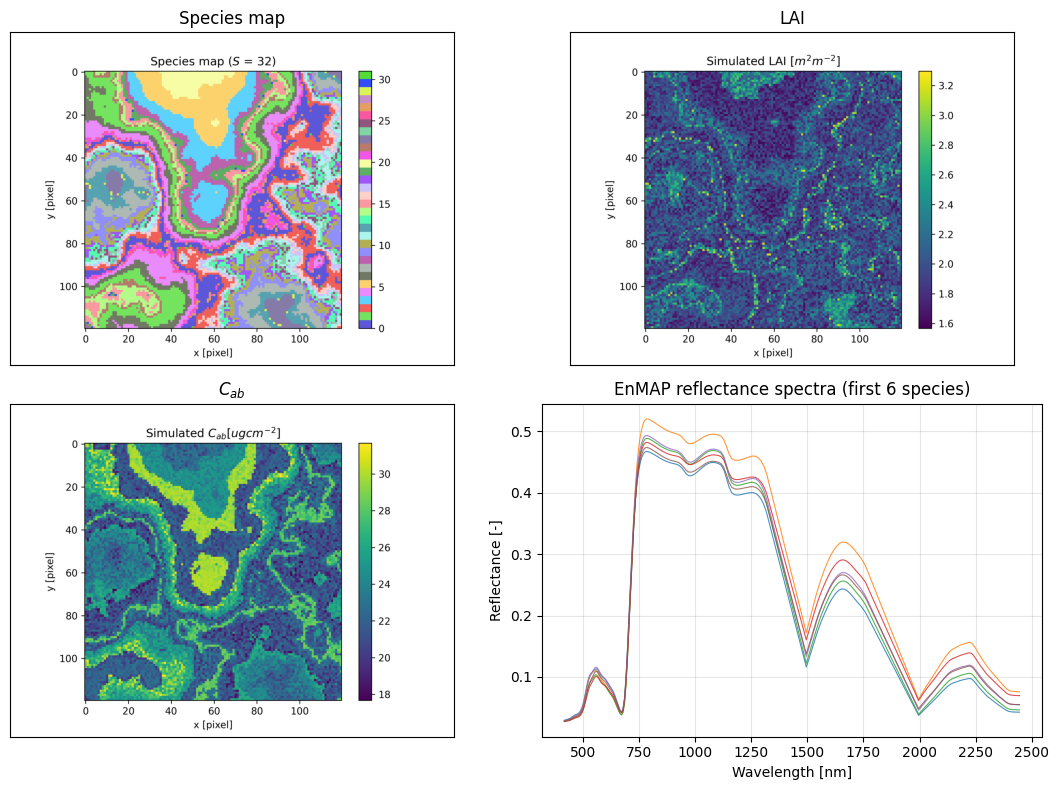

Realized species count S_max = 32; scene 120x120 px


In [ ]:
import matplotlib.pyplot as plt

# Render the maps with the authors' own plotter (saved files), then embed them
bosse_M.show_species_map(title_lb=f'Species map ($S$ = {bosse_M.S_max})',
                         fname='/content/preview_species.png', plt_show=False)
I_lai = bosse_M.all_vars.index('LAI')
I_cab = bosse_M.all_vars.index('Cab')
bosse_M.show_bosse_map(PT_[:, :, I_lai][:bosse_M.scsz_, :bosse_M.scsz_],
                       title_lb='Simulated LAI $[m^2 m^{-2}]$',
                       fname='/content/preview_LAI.png', plt_show=False)
bosse_M.show_bosse_map(PT_[:, :, I_cab][:bosse_M.scsz_, :bosse_M.scsz_],
                       title_lb='Simulated $C_{ab} [ug cm^{-2}]$',
                       fname='/content/preview_Cab.png', plt_show=False)

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for a, f, t in ((ax[0, 0], '/content/preview_species.png', 'Species map'),
                (ax[0, 1], '/content/preview_LAI.png', 'LAI'),
                (ax[1, 0], '/content/preview_Cab.png', '$C_{ab}$')):
    a.imshow(plt.imread(f)); a.set_xticks([]); a.set_yticks([]); a.set_title(t)
for sid in bosse_M.sp_id[:6]:
    m = bosse_M.sp_map == sid
    ax[1, 1].plot(wl, RF_[m].mean(axis=0), lw=.8, alpha=.8)
ax[1, 1].set_xlabel('Wavelength [nm]'); ax[1, 1].set_ylabel('Reflectance [-]')
ax[1, 1].set_title('EnMAP reflectance spectra (first 6 species)')
ax[1, 1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f'Realized species count S_max = {bosse_M.S_max}; scene {bosse_M.scsz_}x{bosse_M.scsz_} px')

## 11 · Apply the uncertainty to the reflectance factors

This reproduces the driver's uncertainty loop for **one realization** (`mci = 0`) of the `constant_decorrelated` type (random Gaussian noise with σ = 5 % of each band's range, spatially and spectrally decorrelated), including the driver's rescaling rule: constant uncertainties are rescaled so that, per band, their RMSE matches the analogous *scaled* (value-relative) uncertainty in this scene (`bosse_run.py` L557–570). The seeds follow the driver's deterministic formula `(ns+1)·(13·(i_+1))·(17·(j_+1+iii_))·(mci+1)` with `ns=0, i_=0, j_=1` → **scaled** (`iii_=4`): 1326, **constant** (`iii_=3`): 1105.

Per the investigation's minimal task, the noise is added **only to the reflectance factors**; the plant-trait map stays unperturbed (the paper's *true error* setting — Method 2.4 compares proxies against unperturbed PT). `simulate_uncertainty` returns a trait perturbation too, which we discard here.

**日本語:** ドライバと同じシード式で `constant_decorrelated`(相対 5 % の定数ランダム誤差)を 1 実現値だけ反射率に加算します。constant 型は scaled 型の RMSE に合わせるようドライバの規則で再スケーリングします。植物形質側は無撹乱のまま(true error 設定)です。

In [ ]:
sc_sz = inputs_['scene_sz']
# driver L548-554: ranges per band / trait, repeated spatially
range_rf_sc = np.repeat(np.repeat(np.ptp(
    RF_.reshape(RF_.shape[0] * RF_.shape[1], RF_.shape[2]), axis=0).reshape(
        1, 1, -1), sc_sz, axis=0), sc_sz, axis=1)
range_pt_sc = np.repeat(np.repeat(np.ptp(
    PT_.reshape(PT_.shape[0] * PT_.shape[1], PT_.shape[2]), axis=0).reshape(
        1, 1, -1), sc_sz, axis=0), sc_sz, axis=1)

def driver_seed(iii_, mci):     # bosse_run.py L538-541
    return (0 + 1) * (13 * (0 + 1)) * (17 * (1 + 1 + iii_)) * (mci + 1)

MCI = 0
# scaled (iii_=4) and constant (iii_=3) decorrelated types, same realization
u_ref_scaled, _ = simulate_uncertainty(
    'scaled_decorrelated', RF_, PT_, range_pt_sc, range_rf_sc,
    driver_seed(4, MCI), constant_decorrelated=0.05)
u_ref_const, _ = simulate_uncertainty(
    'constant_decorrelated', RF_, PT_, range_pt_sc, range_rf_sc,
    driver_seed(3, MCI), constant_decorrelated=0.05)

# driver L557-570: rescale constant to match the scaled variant's per-band RMSE
u_ref = u_ref_const * (cube_var_rmse(u_ref_scaled) /
                       cube_var_rmse(u_ref_const)).reshape((1, 1, -1))

RF_u = RF_ + u_ref
print('relative RMSE of added noise per band: mean %.2f%%, max %.2f%%' % (
    100 * cube_var_rmse(u_ref).mean(), 100 * cube_var_rmse(u_ref).max()))
print('RF_u shape:', RF_u.shape)

relative RMSE of added noise per band: mean 1.11%, max 2.50%
RF_u shape: (120, 120, 197)


## 12 · Recompute the remote-sensing proxies from perturbed reflectance

For both the unperturbed and perturbed reflectance we compute NDVI and NIRv with the author's `get_ndvi_nirv`, and retrieve optical traits (OT) with the EnMAP inversion network `bosse_Mot.pred_opt_traits`, appending a layer of ones times the sun-zenith angle `tts` exactly as the driver does (`bosse_run.py` L441–443). R is the reflectance cube itself.

**日本語:** 無撹乱/撹乱の両反射率から、NDVI・NIRv(get_ndvi_nirv)と光学形質 OT(EnMAP 逆ネットワーク + 太陽天頂角 tts)を著者コードのままで計算します。

In [ ]:
t0 = time.time()
# perturbed proxies
data_u = {'rf': RF_u}
data_u['ndvi'], data_u['nirv'] = get_ndvi_nirv(data_u['rf'], wl)
data_u['ot'] = bosse_Mot.pred_opt_traits(
    np.concatenate((bosse_M.transf3D_2_2D(data_u['rf']),
                    ones_layer * tts), axis=1), sc_sz)
# no-uncertainty proxies
data_0 = {'rf': RF_}
data_0['ndvi'], data_0['nirv'] = get_ndvi_nirv(data_0['rf'], wl)
data_0['ot'] = bosse_Mot.pred_opt_traits(
    np.concatenate((bosse_M.transf3D_2_2D(data_0['rf']),
                    ones_layer * tts), axis=1), sc_sz)
print(f'proxies computed in {time.time() - t0:.1f} s')
print('OT cube:', data_u['ot'].shape, '| NDVI range:',
      round(float(np.nanmin(data_u['ndvi'])), 3), '..',
      round(float(np.nanmax(data_u['ndvi'])), 3))

proxies computed in 0.3 s
OT cube: (120, 120, 12) | NDVI range: 0.753 .. 0.899


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 13 · Compute QRao maps (3×3 window, standardization + PCA 98 %)

`gndi.raoQ_grid` is the authors' QRao implementation used by the driver for every predictor: it standardizes the variables and applies PCA retaining 98 % of the variance (its defaults `wsz_=3, fexp_var_in=.98`), then computes Rao's quadratic entropy in each 3×3 moving window — for a 120×120 scene this yields a (40, 40) grid of 1,600 values, matching Methods 2.3. We compute QRao for the plant traits (reference) and for every proxy, both without and with uncertainty. This is the numerically heaviest step.

**日本語:** 著者の `raoQ_grid`(既定で 3×3 ウィンドウ・標準化・PCA 98 %)により、植物形質(参照)と各リモートセンシング指標の QRao マップを、無撹乱/撹乱の両方で計算します。120×120 → 1,600 個の QRao 値が得られます。

In [ ]:
t0 = time.time()
Q = {'pt': gndi.raoQ_grid(PT_)[0]}
for tag, d in (('0', data_0), ('u', data_u)):
    for pr in ('rf', 'ndvi', 'nirv', 'ot'):
        Q[f'{pr}_{tag}'] = gndi.raoQ_grid(d[pr])[0]
print(f'QRao grids computed in {time.time() - t0:.1f} s')
for k in ('pt', 'rf_0', 'rf_u', 'ndvi_0', 'ndvi_u', 'nirv_0', 'nirv_u',
          'ot_0', 'ot_u'):
    q = Q[k]['RaoQ']
    print(f'  QRao {k:8s} grid {q.shape}, mean {np.nanmean(q):.4f}, '
          f'std {np.nanstd(q):.4f}')

QRao grids computed in 1.7 s
  QRao pt       grid (40, 40), mean 0.0646, std 0.0186
  QRao rf_0     grid (40, 40), mean 0.0722, std 0.0217
  QRao rf_u     grid (40, 40), mean 0.0854, std 0.0149
  QRao ndvi_0   grid (40, 40), mean 0.0728, std 0.0237
  QRao ndvi_u   grid (40, 40), mean 0.0762, std 0.0225
  QRao nirv_0   grid (40, 40), mean 0.0673, std 0.0232
  QRao nirv_u   grid (40, 40), mean 0.0760, std 0.0206
  QRao ot_0     grid (40, 40), mean 0.0629, std 0.0313
  QRao ot_u     grid (40, 40), mean 0.0882, std 0.0144


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 14 · Within-scene agreement: perturbed proxies vs. unperturbed plant-trait QRao

Reproducing the driver's *within*-scene evaluation (`bosse_run.py` L627–630 calls `assess_predobs(Q[pr]['RaoQ'], Q['pt']['RaoQ'])`), we regress each proxy's 1,600 window QRao values (predictor) against the unperturbed plant-trait QRao (observed) and report the author's statistics: R², Pearson r, RMSE, RRMSE, MAE, slope, and intercept (bias). Each predictor is evaluated **without** uncertainty (reference) and **with** the constant decorrelated 5 % noise on reflectance.

**日本語:** ドライバの within シーン評価と同様に、各指標の QRao(1,600 値)を無撹乱植物形質の QRao に回帰し、R²・相関係数・RMSE・RRMSE・MAE・回帰係数を、無撹乱時と撹乱時で比較します。

In [ ]:
obs_ = Q['pt']['RaoQ'].reshape(-1)
rows = []
for pr, lb in (('rf', 'R'), ('ndvi', 'NDVI'), ('nirv', 'NIRv'), ('ot', 'OT')):
    for tag, cond in (('0', 'no uncertainty'), ('u', '5% const. decorrelated')):
        s = assess_predobs(Q[f'{pr}_{tag}']['RaoQ'].reshape(-1), obs_)
        rows.append({'predictor': lb, 'reflectance': cond, 'n': s[0],
                     'R2': s[1], 'r_Pearson': s[2], 'RMSE': s[4],
                     'RRMSE_%': s[5], 'MAE': s[7], 'slope': s[8],
                     'intercept': s[9]})
df_stats = pd.DataFrame(rows)
df_stats_rounded = df_stats.copy()
for c in ('R2', 'r_Pearson', 'RMSE', 'RRMSE_%', 'MAE', 'slope', 'intercept'):
    df_stats_rounded[c] = df_stats_rounded[c].round(4)
print(df_stats_rounded.to_string(index=False))

predictor            reflectance    n      R2  r_Pearson   RMSE  RRMSE_%    MAE  slope  intercept
        R         no uncertainty 1600  0.3516     0.8077 0.0150  23.1418 0.0119 0.6897     0.0148
        R 5% const. decorrelated 1600 -0.6513     0.7748 0.0239  36.9309 0.0212 0.9662    -0.0179
     NDVI         no uncertainty 1600 -0.9184     0.3559 0.0257  39.8055 0.0210 0.2783     0.0444
     NDVI 5% const. decorrelated 1600 -1.2032     0.2715 0.0276  42.6584 0.0223 0.2237     0.0476
     NIRv         no uncertainty 1600 -0.3384     0.4986 0.0215  33.2481 0.0172 0.3987     0.0378
     NIRv 5% const. decorrelated 1600 -0.9442     0.2983 0.0259  40.0729 0.0210 0.2694     0.0441
       OT         no uncertainty 1600 -1.3481     0.4439 0.0285  44.0389 0.0235 0.2636     0.0480
       OT 5% const. decorrelated 1600 -2.0357     0.1184 0.0323  50.0733 0.0265 0.1527     0.0511


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 15 · Visual comparison: QRao maps and scatter

Left to right: the QRao of the unperturbed plant traits (reference), of the perturbed reflectance, and of the perturbed OT retrieval; plus a scatter of window-level QRao(R) against QRao(PT) without and with uncertainty. In the paper's ensemble these regressions degrade (lower R², higher RRMSE) as uncertainty is added, with systematically smaller effects when errors are spatially/spectrally correlated — a single scene-date shows the same direction of effect.

**日本語:** 無撹乱植物形質の QRao、撹乱後の反射率と OT の QRao を並べ、ウィンドウ単位の散布図(無撹乱 vs 撹乱)で影響の方向を確認します。

/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()


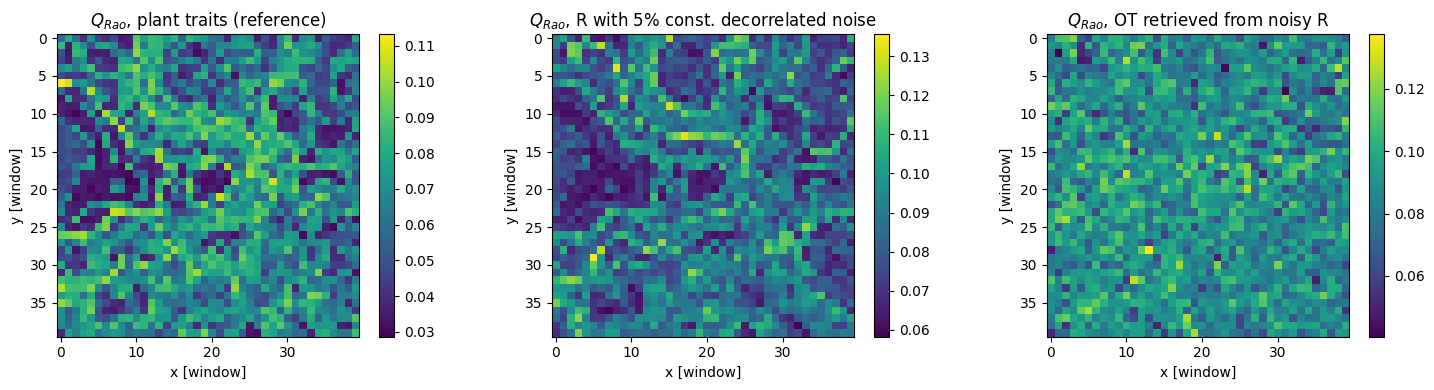

/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()


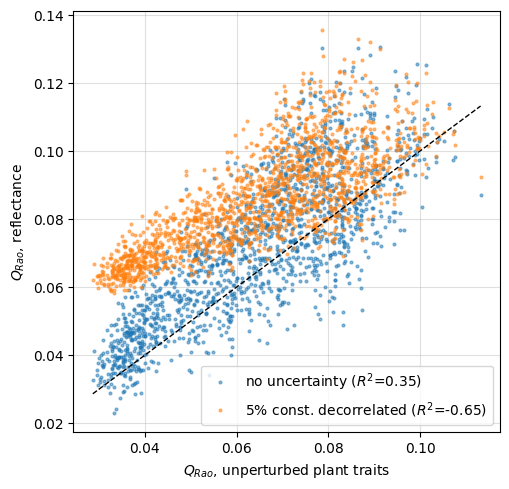

Additional visualization created for this notebook (not an author figure).


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
im0 = ax[0].imshow(Q['pt']['RaoQ'], cmap='viridis')
ax[0].set_title('$Q_{Rao}$, plant traits (reference)'); plt.colorbar(im0, ax=ax[0], fraction=.046)
im1 = ax[1].imshow(Q['rf_u']['RaoQ'], cmap='viridis')
ax[1].set_title('$Q_{Rao}$, R with 5% const. decorrelated noise'); plt.colorbar(im1, ax=ax[1], fraction=.046)
im2 = ax[2].imshow(Q['ot_u']['RaoQ'], cmap='viridis')
ax[2].set_title('$Q_{Rao}$, OT retrieved from noisy R'); plt.colorbar(im2, ax=ax[2], fraction=.046)
for a in ax: a.set_xlabel('x [window]'); a.set_ylabel('y [window]')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.grid(alpha=.4)
s0 = assess_predobs(Q['rf_0']['RaoQ'].reshape(-1), obs_)
su = assess_predobs(Q['rf_u']['RaoQ'].reshape(-1), obs_)
ax.plot(obs_, Q['rf_0']['RaoQ'].reshape(-1), '.', ms=4, alpha=.5,
        label=f'no uncertainty ($R^2$={s0[1]:.2f})')
ax.plot(obs_, Q['rf_u']['RaoQ'].reshape(-1), '.', ms=4, alpha=.5,
        label=f'5% const. decorrelated ($R^2$={su[1]:.2f})')
lims = [np.nanmin(obs_), np.nanmax(obs_)]
ax.plot(lims, lims, 'k--', lw=1)
ax.set_xlabel('$Q_{Rao}$, unperturbed plant traits'); ax.set_ylabel('$Q_{Rao}$, reflectance')
ax.legend(); plt.tight_layout(); plt.show()
print('Additional visualization created for this notebook '
      '(not an author figure).')

## 16 · Export the window-level results

We save the 1,600 window-level QRao pairs (plant traits vs. each proxy, no-uncertainty and perturbed) plus the statistics table as CSV under `/content`, so the numbers behind the plots can be inspected or downloaded.

**日本語:** ウィンドウ単位の QRao 値と統計表を CSV として `/content` に保存します。

In [ ]:
qr_df = pd.DataFrame({('QRao_pt'): obs_})
for pr in ('rf', 'ndvi', 'nirv', 'ot'):
    qr_df[f'QRao_{pr}_noUnc'] = Q[f'{pr}_0']['RaoQ'].reshape(-1)
    qr_df[f'QRao_{pr}_5pctConstDecorr'] = Q[f'{pr}_u']['RaoQ'].reshape(-1)
qr_df.to_csv('/content/qrao_window_results.csv', index=False)
df_stats.to_csv('/content/qrao_statistics.csv', index=False)
print('saved /content/qrao_window_results.csv', qr_df.shape)
print('saved /content/qrao_statistics.csv', df_stats.shape)
qr_df.describe().round(4)

saved /content/qrao_window_results.csv (1600, 9)
saved /content/qrao_statistics.csv (8, 10)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,QRao_pt,QRao_rf_noUnc,QRao_rf_5pctConstDecorr,QRao_ndvi_noUnc,QRao_ndvi_5pctConstDecorr,QRao_nirv_noUnc,QRao_nirv_5pctConstDecorr,QRao_ot_noUnc,QRao_ot_5pctConstDecorr
count,1600.0000,1600.0000,1600.0000,1600.0000,1600.0000,1600.0000,1600.0000,1600.0000,1600.0000
mean,0.0646,0.0722,0.0854,0.0728,0.0762,0.0673,0.0760,0.0629,0.0882
std,0.0186,0.0217,0.0149,0.0238,0.0225,0.0232,0.0206,0.0313,0.0144
min,0.0286,0.0231,0.0583,0.0199,0.0219,0.0140,0.0143,0.0131,0.0405
25%,0.0495,0.0551,0.0734,0.0557,0.0603,0.0501,0.0614,0.0375,0.0788
50%,0.0667,0.0719,0.0842,0.0691,0.0743,0.0642,0.0746,0.0577,0.0885
75%,0.0790,0.0887,0.0957,0.0875,0.0898,0.0814,0.0896,0.0880,0.0978
max,0.1132,0.1307,0.1356,0.1532,0.1623,0.1709,0.1674,0.1395,0.1375


## Interpretation and limitations

**What was executed.** A single deterministic BOSSE scene-date (Continental, intermediate pattern, site 0, seed 1, peak-GSI date) simulated with the authors' pinned code; constant decorrelated 5 % noise added to the EnMAP reflectance factors with the driver's rescaling rule; NDVI/NIRv/OT recomputed from the noisy reflectance; QRao maps computed with pyGNDiv's 3×3 window, standardization + PCA 98 %; and the window-level agreement with the unperturbed plant-trait QRao summarized with the driver's own statistics.

**How to read it.** Compare each predictor's *no uncertainty* row with its *5 % const. decorrelated* row in the statistics table: adding reflectance noise degrades within-scene agreement (lower R²/r, higher RMSE/RRMSE). In the paper's 180-scene ensemble the same qualitative behavior appears for all proxies, with impacts up to 3× larger for random than systematic uncertainties, and reduced impacts when errors are correlated. One scene-date cannot quantify those ensemble-level effects.

**Limitations.** Single scene, single date, single realization, single uncertainty type; traits deliberately unperturbed (true-error setting only — the apparent-error variant perturbs PT as well); SVI3 and the no-preprocessing sensitivity are omitted; free-tier Colab hardware varies.

**Provenance.** pyBOSSE `2ae90057dedbc477fdf4463e2aa638d0bbbf54fc` (GPL-3), pyGNDiv `11167fe8b0574982029d1961801d85971e1283fe` (LGPL-3), driver `bosse_run.py` md5 `c95d512d3034d246788764ce52c4b527` from Zenodo 10.5281/zenodo.22872340; meteorology `BOSSE_meteo_Continental_0.nc` from the pinned repository. Paper: bioRxiv 2026-09-22, doi 10.64898/2026.09.21.753123.

**日本語:** 実行したのは 1 シーン・1 日・1 実現値・1 種類の不確実性の最小デモです。統計表で「無撹乱」と「5 % 定数非相関」の行を比較すると、反射率ノイズによって QRao の一致度(R²・r)が低下し RMSE/RRMSE が増大する方向が確認できます。論文のアンサンブル規模の結論の定量化は対象外です。